# AAPL — six-model, five-seed experiment
Train price-only and news-enhanced versions of LSTM, Transformer and GRU independently with each of five preselected seeds (42, 123, 456, 789, 2026). The chronological 70/15/15 split, intraday return target, price and news features, training-only scaling, full-batch Adam (0.001), 100 epochs and model architectures are unchanged except for the input width of enhanced models. Compare average performance, sample standard deviations and paired changes for all three architectures. The same-day high and low are inputs, so this remains **same-day closing-price estimation**, not advance forecasting. News inputs combine prior-date sentiment, counts and availability; the experiment evaluates the combined news feature set, not sentiment in isolation. Use only news authorized for research. Keep final validation disabled until all decisions are frozen. GPU and CPU results may differ slightly.

## Yahoo Finace Libaray

In [1]:
!pip install -q yfinance

import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# Download AAPL once; exploratory plots use training dates only
stock_symbol = "AAPL"
start_date = "2013-01-01"
end_date = "2023-01-01"

raw_download = yf.download(
    stock_symbol, start=start_date, end=end_date,
    auto_adjust=False, progress=False
)

if raw_download.empty:
    raise ValueError("AAPL download failed.")
if isinstance(raw_download.columns, pd.MultiIndex):
    raw_download.columns = raw_download.columns.get_level_values(0)

raw_download = raw_download.sort_index()
raw_download.index.name = "Date"

# Keep exploratory plots and outlier checks away from the holdout
stock_data = raw_download.iloc[:int(len(raw_download) * 0.70)].copy()
stock_data = stock_data.reset_index()


## Plot historical data

In [3]:
import time
from datetime import datetime
import plotly.express as px
import pandas as pd

# Fix yfinance MultiIndex columns
if isinstance(stock_data.columns, pd.MultiIndex):
    stock_data.columns = stock_data.columns.get_level_values(0)

# Make sure Date is a column
if "Date" not in stock_data.columns:
    stock_data = stock_data.reset_index()

def plot_stock_data(data, title):
    '''Function for plotting stock data'''
    plot = px.line(
        data,
        x="Date",
        y="Close",
        hover_name="Date",
        line_shape="linear",
        title=title
    )
    return plot

plot_stock_data(stock_data[-30:], "AAPL Stock Prices")


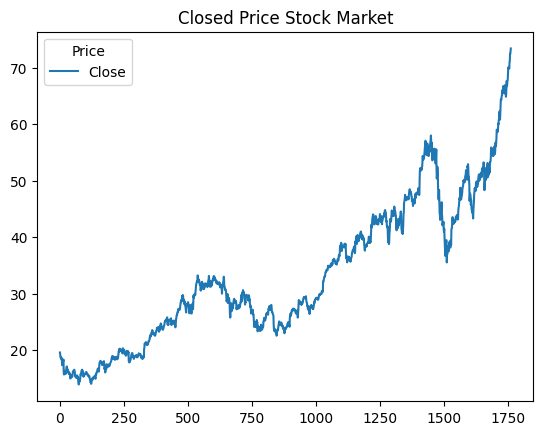

In [4]:
stock_data[['Close']].plot()
plt.title("Closed Price Stock Market")
plt.show()

## Outlier checking

In [5]:
# Create df from the existing stock dataset
df = stock_data.copy()

# Convert the Date column to datetime
df['Date'] = pd.to_datetime(df['Date'])

# Display the dataset
df


Price,Date,Adj Close,Close,High,Low,Open,Volume
0,2013-01-02,16.554537,19.608213,19.821428,19.343929,19.779285,560518000
1,2013-01-03,16.345577,19.360714,19.631071,19.321428,19.567142,352965200
2,2013-01-04,15.890280,18.821428,19.236786,18.779642,19.177500,594333600
3,2013-01-07,15.796803,18.710714,18.903570,18.400000,18.642857,484156400
4,2013-01-08,15.839318,18.761070,18.996071,18.616072,18.900356,458707200
...,...,...,...,...,...,...,...
1757,2019-12-24,68.350380,71.067497,71.222504,70.730003,71.172501,48478800
1758,2019-12-26,69.706459,72.477501,72.495003,71.175003,71.205002,93121200
1759,2019-12-27,69.680000,72.449997,73.492500,72.029999,72.779999,146266000
1760,2019-12-30,70.093575,72.879997,73.172501,71.305000,72.364998,144114400


In [6]:
# Specify the column to analyze for outliers
column_name = 'Open'

# Calculate the IQR (Interquartile Range)
Q1 = df[column_name].quantile(0.25)
Q3 = df[column_name].quantile(0.75)
IQR = Q3 - Q1

# Define the lower and upper bounds for outliers
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Identify and count outliers
outliers = df[(df[column_name] < lower_bound) | (df[column_name] > upper_bound)]
num_outliers = len(outliers)

# Display the number of outliers
print(f'Number of outliers in {column_name}: {num_outliers}')


Number of outliers in Open: 3


In [7]:
# Specify the column to analyze for outliers
column_name = 'Close'

# Calculate the IQR (Interquartile Range)
Q1 = df[column_name].quantile(0.25)
Q3 = df[column_name].quantile(0.75)
IQR = Q3 - Q1

# Define the lower and upper bounds for outliers
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Identify and count outliers
outliers = df[(df[column_name] < lower_bound) | (df[column_name] > upper_bound)]
num_outliers = len(outliers)

# Display the number of outliers
print(f'Number of outliers in {column_name}: {num_outliers}')


Number of outliers in Close: 4


/usr/local/lib/python3.13/dist-packages/seaborn/_base.py:1608: UserWarning:

Vertical orientation ignored with only `x` specified.

/tmp/ipykernel_1098/2118448779.py:10: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.




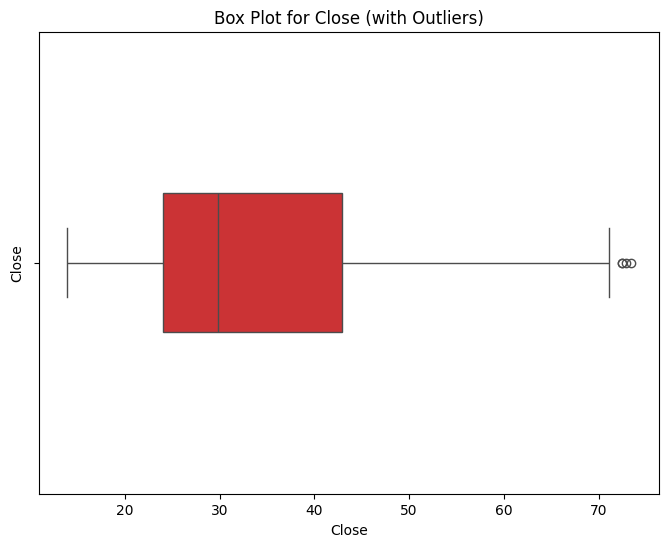

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns


# Specify the column to visualize outliers
column_name = 'Close'

# Create a box plot to visualize outliers
plt.figure(figsize=(8, 6))
sns.boxplot(x=df[column_name], orient='v', width=0.3, palette='Set1')
plt.title(f'Box Plot for {column_name} (with Outliers)')
plt.ylabel(column_name)
plt.show()


## Shared AAPL preprocessing (70% training / 15% testing / 15% final validation)


In [9]:
import torch
import numpy as np
import pandas as pd
import yfinance as yf
from google.colab import files

torch.manual_seed(42)
np.random.seed(42)

# Reuse the AAPL download from the first data cell.
# Exploration used only the training portion.
raw = raw_download.copy()

raw = raw.rename(
    columns={"Adj Close": "Adjusted Close"}
)

columns_to_normalize = [
    "Low", "Open", "Volume",
    "High", "Close", "Adjusted Close"
]

raw = raw[columns_to_normalize].sort_index().copy()
raw.index.name = "Date"

if raw.isna().any().any():
    raise ValueError("Missing AAPL stock values")

# Split chronologically: 70/15/15
train_size = int(len(raw) * 0.70)
test_size = int(len(raw) * 0.15)

train_raw = raw.iloc[:train_size].copy()
test_raw = raw.iloc[
    train_size:train_size + test_size
].copy()
val_raw = raw.iloc[
    train_size + test_size:
].copy()

# Export original stock data
train_raw.to_csv("AAPL_Training.csv")
test_raw.to_csv("AAPL_Testing.csv")
val_raw.to_csv("AAPL_Validation.csv")

print("Training:", len(train_raw))
print("Testing:", len(test_raw))
print("Validation:", len(val_raw))

# Express prices relative to the opening price or previous close.
# shift(1) uses only the previous trading day's close, even at split boundaries.
assert (raw["Open"] > 0).all() and (raw["Close"] > 0).all()
previous_close = raw["Close"].shift(1)
feature_columns = ["Low_vs_Open_pct", "Open_vs_Prev_Close_pct", "High_vs_Open_pct"]
target_column = "Close_vs_Open_pct"

def make_price_features(frame, prev_close):
    out = pd.DataFrame(index=frame.index)
    out["Low_vs_Open_pct"] = (frame["Low"] / frame["Open"] - 1) * 100
    out["Open_vs_Prev_Close_pct"] = (frame["Open"] / prev_close - 1) * 100
    out["High_vs_Open_pct"] = (frame["High"] / frame["Open"] - 1) * 100
    return out

def make_return_target(frame):
    return (frame["Close"] / frame["Open"] - 1) * 100

train_price = make_price_features(train_raw, previous_close.loc[train_raw.index])
test_price = make_price_features(test_raw, previous_close.loc[test_raw.index])
# No preceding observation exists for the first training day.
train_price.loc[train_price.index[0], "Open_vs_Prev_Close_pct"] = 0.0
train_return = make_return_target(train_raw)
test_return = make_return_target(test_raw)

# Fit separate input and target scalers ONLY on training observations.
price_mean = train_price.mean()
price_std = train_price.std(ddof=0).replace(0, 1)
return_mean = float(train_return.mean())
return_std = float(train_return.std(ddof=0)) or 1.0

def price_tensor(frame):
    normalized = (frame[feature_columns] - price_mean) / price_std
    if not np.isfinite(normalized.to_numpy()).all():
        raise ValueError("Invalid normalized price features")
    return torch.tensor(normalized.to_numpy(), dtype=torch.float32)

def target_tensor(returns):
    return torch.tensor((returns.to_numpy() - return_mean) / return_std, dtype=torch.float32)

def to_original_returns(values):
    return np.asarray(values).reshape(-1) * return_std + return_mean

def to_original_prices(values, opens):
    returns = to_original_returns(values)
    opens = np.asarray(opens).reshape(-1)
    if len(returns) != len(opens):
        raise ValueError("Return predictions and opening prices do not align")
    return opens * (1 + returns / 100)

train_features = price_tensor(train_price)
test_features = price_tensor(test_price)
train_target = target_tensor(train_return)
test_target = target_tensor(test_return)

print("Training price-feature shape:", train_features.shape)
print("Training return mean/std (%):", return_mean, return_std)
print("Raw split CSVs saved in the Colab Files panel.")
# The original raw CSVs are saved as before; no need to download them again.

Training: 1762
Testing: 377
Validation: 379
Training price-feature shape: torch.Size([1762, 3])
Training return mean/std (%): 0.02852230583082677 1.2026734795284968
Raw split CSVs saved in the Colab Files panel.


## Model architectures (unchanged)

In [10]:
import torch.nn as nn
import torch.optim as optim

class LSTMModel(nn.Module):
    def __init__(
        self, input_size, hidden_size,
        output_size, num_layers
    ):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size,
            hidden_size,
            num_layers,
            batch_first=True
        )

        self.fc_output = nn.Linear(
            hidden_size, output_size
        )

    def forward(self, x):
        _, (hn, _) = self.lstm(x)
        return self.fc_output(hn[-1, :, :])

class TransformerModel(nn.Module):
    def __init__(
        self, input_size, hidden_size,
        output_size, num_layers,
        num_attention_heads
    ):
        super().__init__()

        self.embedding = nn.Linear(
            input_size, hidden_size
        )

        self.transformer = nn.Transformer(
            d_model=hidden_size,
            nhead=num_attention_heads,
            num_encoder_layers=num_layers,
            num_decoder_layers=num_layers
        )

        self.fc_output = nn.Linear(
            hidden_size, output_size
        )

    def forward(self, x):
        x = self.embedding(x)
        x = x.permute(1, 0, 2)
        x = self.transformer(x, x)
        x = x.permute(1, 0, 2)

        return self.fc_output(
            x[:, -1, :]
        )

class GRUModel(nn.Module):
    def __init__(self, input_size, hidden_size,
                 num_layers, output_size):

        super(GRUModel, self).__init__()

        self.gru = nn.GRU(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True
        )

        self.fc = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        gru_output, hidden = self.gru(x)
        return self.fc(gru_output[:, -1, :])

## Prepare the existing FinBERT CSV
Upload `AAPL_FinBERT_Sentiment_2013_2022.csv` if prompted. No need to rerun FinBERT.

In [11]:
import os
import pandas as pd
import numpy as np
import torch
from google.colab import files

NEWS_FILE = "AAPL_FinBERT_Sentiment_2013_2022.csv"

if not os.path.exists(NEWS_FILE):
    uploaded = files.upload()
    if NEWS_FILE not in uploaded:
        raise FileNotFoundError(f"Please upload {NEWS_FILE}")

scored_news = pd.read_csv(NEWS_FILE)

required = {"date", "Sentiment"}
if not required.issubset(scored_news.columns):
    raise ValueError("News CSV must contain date and Sentiment columns.")

# Preserve the supplied publication calendar date
scored_news["date"] = pd.to_datetime(
    scored_news["date"].astype(str).str[:10], errors="coerce"
)
scored_news["Sentiment"] = pd.to_numeric(
    scored_news["Sentiment"], errors="coerce"
)

if scored_news[["date", "Sentiment"]].isna().any().any():
    raise ValueError("Invalid date or sentiment in the news CSV.")
if not scored_news["Sentiment"].between(-1, 1).all():
    raise ValueError("Expected FinBERT sentiment scores in [-1, 1].")

scored_news = scored_news.sort_values("date").reset_index(drop=True)
if "relevant_text" in scored_news.columns:
    scored_news = scored_news.drop_duplicates(["date", "relevant_text"])

if scored_news.empty:
    raise ValueError("No scored news records.")

def make_news_features(dates, articles):
    dates = pd.DatetimeIndex(dates).normalize()
    if dates.tz is not None:
        dates = dates.tz_localize(None)

    articles = articles.sort_values("date")
    news_dates = pd.DatetimeIndex(articles["date"])
    scores = articles["Sentiment"].to_numpy(dtype=np.float64)
    prefix = np.r_[0.0, np.cumsum(scores)]
    result = pd.DataFrame(index=dates)

    for window in (1, 3, 7):
        left = news_dates.searchsorted(
            dates - pd.Timedelta(days=window), side="left"
        )
        right = news_dates.searchsorted(dates, side="left")
        count = right - left
        total = prefix[right] - prefix[left]

        result[f"Sentiment_{window}D"] = np.divide(
            total, count, out=np.zeros(len(dates)), where=count > 0
        )
        result[f"Has_News_{window}D"] = (count > 0).astype(float)

        if window == 7:
            result["Log_News_Count_7D"] = np.log1p(count)

    return result

news_numeric = [
    "Sentiment_1D", "Sentiment_3D", "Sentiment_7D",
    "Log_News_Count_7D"
]
news_flags = ["Has_News_1D", "Has_News_3D", "Has_News_7D"]
news_columns = news_numeric + news_flags

# Restrict development news to dates before the last development target
development_news = scored_news[
    scored_news["date"] < pd.Timestamp(test_raw.index[-1]).normalize()
].copy()

train_news = make_news_features(train_raw.index, development_news)
test_news = make_news_features(test_raw.index, development_news)

# Fit the news scaler on training data only
news_mean = train_news[news_numeric].mean()
news_std = train_news[news_numeric].std(ddof=0).replace(0, 1)

def news_tensor(frame):
    features = frame[news_columns].copy()
    features[news_numeric] = (
        features[news_numeric] - news_mean
    ) / news_std
    return torch.tensor(features.to_numpy(), dtype=torch.float32)

# All rows stay in chronological order, including those without news
assert len(train_news) == len(train_features)
assert len(test_news) == len(test_features)

train_features_enhanced = torch.cat(
    [train_features, news_tensor(train_news)], dim=1
)
test_features_enhanced = torch.cat(
    [test_features, news_tensor(test_news)], dim=1
)

print("Price-only training shape:", tuple(train_features.shape))
print("Enhanced training shape:", tuple(train_features_enhanced.shape))
print("Enhanced testing shape:", tuple(test_features_enhanced.shape))
print("Training news coverage:")
print((train_news[news_flags].mean() * 100).round(2))
print("Testing news coverage:")
print((test_news[news_flags].mean() * 100).round(2))


Saving AAPL_FinBERT_Sentiment_2013_2022.csv to AAPL_FinBERT_Sentiment_2013_2022.csv
Price-only training shape: (1762, 3)
Enhanced training shape: (1762, 10)
Enhanced testing shape: (377, 10)
Training news coverage:
Has_News_1D    67.99
Has_News_3D    88.54
Has_News_7D    97.84
dtype: float64
Testing news coverage:
Has_News_1D     82.49
Has_News_3D     98.41
Has_News_7D    100.00
dtype: float64


## Evaluation functions

In [12]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Evaluate dollar closing prices and percentage-point intraday returns separately.
def price_metrics(actual, predicted):
    actual, predicted = np.asarray(actual), np.asarray(predicted)
    mse = mean_squared_error(actual, predicted)
    return {"MAE ($)": mean_absolute_error(actual, predicted),
            "MSE ($²)": mse, "RMSE ($)": np.sqrt(mse),
            "MAPE (%)": np.mean(np.abs((actual - predicted) / actual)) * 100,
            "R²": r2_score(actual, predicted)}

def return_metrics(actual, predicted):
    mse = mean_squared_error(actual, predicted)
    return {"MAE (pp)": mean_absolute_error(actual, predicted),
            "RMSE (pp)": np.sqrt(mse), "R²": r2_score(actual, predicted)}

def compare_models(frame, normalized_predictions):
    opens = frame["Open"].to_numpy()
    actual = frame["Close"].to_numpy()
    actual_returns = make_return_target(frame).to_numpy()
    predicted_prices = {name: to_original_prices(values, opens)
                        for name, values in normalized_predictions.items()}
    predicted_returns = {name: to_original_returns(values)
                         for name, values in normalized_predictions.items()}
    # Simple reference models; midpoint uses same-day High and Low.
    for name, baseline in {"Opening price": opens,
                           "High-Low midpoint": ((frame["High"] + frame["Low"]) / 2).to_numpy()}.items():
        predicted_prices[name] = baseline
        predicted_returns[name] = (baseline / opens - 1) * 100
    prices = pd.DataFrame({name: price_metrics(actual, pred)
                           for name, pred in predicted_prices.items()}).T
    returns = pd.DataFrame({name: return_metrics(actual_returns, pred)
                            for name, pred in predicted_returns.items()}).T
    return prices, returns, predicted_prices, predicted_returns



## Five-seed experiment across six models
A new model and optimizer are created for each of the 30 runs. Every model uses the same five seeds. There is no test-based early stopping or seed selection. Enhanced variants differ from their price-only counterparts in input width. GPU is used if available. Model weights and development metrics are saved after each run. Deterministic opening-price and midpoint benchmarks are evaluated once.

In [13]:
import random
from pathlib import Path

SEEDS = [42, 123, 456, 789, 2026]
EPOCHS = 100
LEARNING_RATE = 0.001
USE_GPU = True
DEVICE = torch.device("cuda" if USE_GPU and torch.cuda.is_available() else "cpu")
print("Training device:", DEVICE)

CHECKPOINT_DIR = Path("AAPL_6Model_5Seed_Checkpoints")
CHECKPOINT_DIR.mkdir(exist_ok=True)

ARCHITECTURES = ["LSTM", "Transformer", "GRU"]
MODEL_NAMES = [name for architecture in ARCHITECTURES
               for name in (architecture, f"Enhanced {architecture}")]
PRICE_INPUT_SIZE = train_features.shape[1]
ENHANCED_INPUT_SIZE = train_features_enhanced.shape[1]
assert PRICE_INPUT_SIZE == 3 and ENHANCED_INPUT_SIZE == 10

model_factories = {
    "LSTM": lambda: LSTMModel(PRICE_INPUT_SIZE, 64, 1, 2),
    "Enhanced LSTM": lambda: LSTMModel(ENHANCED_INPUT_SIZE, 64, 1, 2),
    "Transformer": lambda: TransformerModel(PRICE_INPUT_SIZE, 64, 1, 2, 4),
    "Enhanced Transformer": lambda: TransformerModel(ENHANCED_INPUT_SIZE, 64, 1, 2, 4),
    "GRU": lambda: GRUModel(PRICE_INPUT_SIZE, 64, 2, 1),
    "Enhanced GRU": lambda: GRUModel(ENHANCED_INPUT_SIZE, 64, 2, 1)
}

def select_features(name, price_only, enhanced):
    return enhanced if name.startswith("Enhanced ") else price_only

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

def fit_one_model(name, seed):
    # Reset before constructing each model to avoid carryover between runs.
    set_seed(seed)
    model = model_factories[name]().to(DEVICE)
    optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)
    criterion = nn.MSELoss()
    features = select_features(name, train_features, train_features_enhanced)
    x = features.unsqueeze(1).to(DEVICE)
    y = train_target.unsqueeze(1).to(DEVICE)
    for epoch in range(EPOCHS):
        model.train()
        optimizer.zero_grad()
        loss = criterion(model(x), y)
        loss.backward()
        optimizer.step()
    return model

def predict_normalized(model, features):
    model.eval()
    with torch.no_grad():
        return model(features.unsqueeze(1).to(DEVICE)).squeeze(1).cpu().numpy()

def checkpoint_path(name, seed):
    return CHECKPOINT_DIR / f"{name.replace(' ', '_')}_{seed}.pt"

def metric_row(name, seed, frame, pred):
    price = price_metrics(frame["Close"].to_numpy(), to_original_prices(pred, frame["Open"]))
    ret = return_metrics(make_return_target(frame).to_numpy(), to_original_returns(pred))
    return {"Model": name, "Seed": seed,
            **{f"Price {k}": v for k, v in price.items()},
            **{f"Return {k}": v for k, v in ret.items()}}

assert np.allclose(to_original_prices(test_target.numpy(), test_raw["Open"]),
                   test_raw["Close"].to_numpy(), atol=1e-4)

# Always start fresh: no reuse of previously trained model weights.
rows = []
for seed in SEEDS:
    for name in MODEL_NAMES:
        model = fit_one_model(name, seed)
        x_test = select_features(name, test_features, test_features_enhanced)
        pred = predict_normalized(model, x_test)
        row = metric_row(name, seed, test_raw, pred)
        if not np.isfinite(list(row.values())[2:]).all():
            raise ValueError(f"Non-finite metrics for {name}, seed {seed}")
        rows.append(row)
        torch.save({k: v.detach().cpu() for k, v in model.state_dict().items()},
                   checkpoint_path(name, seed))
        pd.DataFrame(rows).to_csv("AAPL_6Model_5Seed_Per_Run.csv", index=False)
        print(f"Completed {len(rows)}/{len(SEEDS)*len(MODEL_NAMES)} | {name} | seed {seed} | "
              f"price RMSE ${row['Price RMSE ($)']:.4f} | return RMSE {row['Return RMSE (pp)']:.4f} pp", flush=True)
        del model

seed_results = pd.DataFrame(rows)
assert len(seed_results) == len(SEEDS) * len(MODEL_NAMES)
assert not seed_results.duplicated(["Model", "Seed"]).any()


Training device: cpu
Completed 1/30 | LSTM | seed 42 | price RMSE $0.9271 | return RMSE 0.9460 pp
Completed 2/30 | Enhanced LSTM | seed 42 | price RMSE $0.9399 | return RMSE 0.9548 pp


/usr/local/lib/python3.13/dist-packages/torch/nn/modules/transformer.py:145: UserWarning:

enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.batch_first was not True(use batch_first for better inference performance)



Completed 3/30 | Transformer | seed 42 | price RMSE $1.0905 | return RMSE 1.1731 pp


/usr/local/lib/python3.13/dist-packages/torch/nn/modules/transformer.py:145: UserWarning:

enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.batch_first was not True(use batch_first for better inference performance)



Completed 4/30 | Enhanced Transformer | seed 42 | price RMSE $1.0464 | return RMSE 1.0659 pp
Completed 5/30 | GRU | seed 42 | price RMSE $0.9198 | return RMSE 0.9329 pp
Completed 6/30 | Enhanced GRU | seed 42 | price RMSE $0.9238 | return RMSE 0.9314 pp
Completed 7/30 | LSTM | seed 123 | price RMSE $0.9315 | return RMSE 0.9480 pp
Completed 8/30 | Enhanced LSTM | seed 123 | price RMSE $0.9357 | return RMSE 0.9486 pp


/usr/local/lib/python3.13/dist-packages/torch/nn/modules/transformer.py:145: UserWarning:

enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.batch_first was not True(use batch_first for better inference performance)



... (11 outputs left out)

/usr/local/lib/python3.13/dist-packages/torch/nn/modules/transformer.py:145: UserWarning:

enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.batch_first was not True(use batch_first for better inference performance)



Completed 27/30 | Transformer | seed 2026 | price RMSE $0.9877 | return RMSE 1.0209 pp


/usr/local/lib/python3.13/dist-packages/torch/nn/modules/transformer.py:145: UserWarning:

enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.batch_first was not True(use batch_first for better inference performance)



Completed 28/30 | Enhanced Transformer | seed 2026 | price RMSE $1.0134 | return RMSE 1.0193 pp
Completed 29/30 | GRU | seed 2026 | price RMSE $0.9176 | return RMSE 0.9350 pp
Completed 30/30 | Enhanced GRU | seed 2026 | price RMSE $0.9109 | return RMSE 0.9175 pp


## Aggregate results and paired differences
Lower MAE/MSE/RMSE/MAPE is better; higher R² is better. Standard deviations use n−1. A positive paired improvement favors the enhanced model. R² differences are absolute (not percentage changes). Seed variation reflects training randomness on the same development dates, not independent out-of-sample evidence.

DOLLAR CLOSING PRICES — mean and sample standard deviation


,MAE ($) mean,MAE ($) std,MSE ($²) mean,MSE ($²) std,RMSE ($) mean,RMSE ($) std,MAPE (%) mean,MAPE (%) std,R² mean,R² std
Model,,,,,,,,,,
LSTM,0.658171,0.000875,0.868295,0.005956,0.931819,0.003198,0.651599,0.000819,0.998496,0.000010
Enhanced LSTM,0.661462,0.005015,0.869698,0.011402,0.932560,0.006115,0.653999,0.005283,0.998494,0.000020
Transformer,0.648764,0.006390,1.068298,0.087172,1.032902,0.042012,0.646053,0.007441,0.998150,0.000151
Enhanced Transformer,0.654961,0.007514,1.077318,0.035732,1.037825,0.017237,0.645784,0.009511,0.998134,0.000062
GRU,0.640824,0.001931,0.844308,0.003338,0.918861,0.001816,0.632825,0.002214,0.998538,0.000006
Enhanced GRU,0.637644,0.001242,0.839966,0.008799,0.916486,0.004794,0.628606,0.001380,0.998545,0.000015


INTRADAY RETURNS — mean and sample standard deviation


,MAE (pp) mean,MAE (pp) std,RMSE (pp) mean,RMSE (pp) std,R² mean,R² std
Model,,,,,,
LSTM,0.651219,0.000876,0.949459,0.003058,0.727068,0.001759
Enhanced LSTM,0.653584,0.005201,0.944026,0.008125,0.730169,0.004648
Transformer,0.646564,0.007833,1.082111,0.059712,0.644615,0.039697
Enhanced Transformer,0.646363,0.009753,1.052690,0.027145,0.664316,0.017353
GRU,0.632687,0.002107,0.932984,0.002222,0.736459,0.001255
Enhanced GRU,0.628507,0.001372,0.923920,0.005165,0.741549,0.002892


PAIRED RMSE COMPARISON BY SEED — positive reduction favors news-enhanced model


,Architecture,Seed,Metric,Price-only,Enhanced,Improvement (absolute),Improvement (%)
0,LSTM,42,Price RMSE ($),0.927063,0.939894,-0.012831,-1.384046
1,LSTM,123,Price RMSE ($),0.931498,0.935722,-0.004224,-0.453468
2,LSTM,456,Price RMSE ($),0.935704,0.925760,0.009945,1.062810
3,LSTM,789,Price RMSE ($),0.931328,0.926667,0.004661,0.500425
4,LSTM,2026,Price RMSE ($),0.933503,0.934758,-0.001255,-0.134433
5,LSTM,42,Return RMSE (pp),0.945986,0.954849,-0.008863,-0.936917
6,LSTM,123,Return RMSE (pp),0.947980,0.948568,-0.000588,-0.062040
7,LSTM,456,Return RMSE (pp),0.953942,0.936253,0.017690,1.854369
8,LSTM,789,Return RMSE (pp),0.948480,0.935928,0.012553,1.323469
9,LSTM,2026,Return RMSE (pp),0.950907,0.944531,0.006376,0.670534


PAIRED IMPROVEMENT SUMMARY — ALL METRICS


Mean_Absolute_Improvement  \
Architecture Metric                                        
LSTM         Price MAE ($)                     -0.003290   
             Price MSE ($²)                    -0.001403   
             Price RMSE ($)                    -0.000741   
             Price MAPE (%)                    -0.002400   
             Price R²                          -0.000002   
             Return MAE (pp)                   -0.002365   
             Return RMSE (pp)                   0.005433   
             Return R²                          0.003101   
Transformer  Price MAE ($)                     -0.006197   
             Price MSE ($²)                    -0.009020   
             Price RMSE ($)                    -0.004923   
             Price MAPE (%)                     0.000269   
             Price R²                          -0.000016   
             Return MAE (pp)                    0.000201   
             Return RMSE (pp)                   0.029421   
             Return R²                          0.019701   
GRU          Price MAE ($)                      0.003180   
             Price MSE ($²)                     0.004342   
             Price RMSE ($)                     0.002375   
             Price MAPE (%)                     0.004218   
             Price R²                           0.000008   
             Return MAE (pp)                    0.004179   
             Return RMSE (pp)                   0.009064   
             Return R²                          0.005091   

                               SD_Absolute_Improvement  \
Architecture Metric                                      
LSTM         Price MAE ($)                    0.004919   
             Price MSE ($²)                   0.016197   
             Price RMSE ($)                   0.008688   
             Price MAPE (%)                   0.005056   
             Price R²                         0.000028   
             Return MAE (pp)                  0.004978   
             Return RMSE (pp)                 0.010517   
             Return R²                        0.006025   
Transformer  Price MAE ($)                    0.009658   
             Price MSE ($²)                   0.085090   
             Price RMSE ($)                   0.040897   
             Price MAPE (%)                   0.010720   
             Price R²                         0.000147   
             Return MAE (pp)                  0.011099   
             Return RMSE (pp)                 0.060261   
             Return R²                        0.040033   
GRU          Price MAE ($)                    0.002169   
             Price MSE ($²)                   0.007820   
             Price RMSE ($)                   0.004259   
             Price MAPE (%)                   0.002473   
             Price R²                         0.000014   
             Return MAE (pp)                  0.002442   
             Return RMSE (pp)                 0.006501   
             Return R²                        0.003647   

                               Mean_Percent_Improvement  \
Architecture Metric                                       
LSTM         Price MAE ($)                    -0.499915   
             Price MSE ($²)                   -0.170524   
             Price RMSE ($)                   -0.081743   
             Price MAPE (%)                   -0.368209   
             Price R²                               NaN   
             Return MAE (pp)                  -0.363011   
             Return RMSE (pp)                  0.569883   
             Return R²                              NaN   
Transformer  Price MAE ($)                    -0.962585   
             Price MSE ($²)                   -1.318610   
             Price RMSE ($)                   -0.594199   
             Price MAPE (%)                    0.033937   
             Price R²                               NaN   
             Return MAE (pp)                   0.022561   
             Retu

DETERMINISTIC BENCHMARKS (same for all seeds)


,MAE ($),MSE ($²),RMSE ($),MAPE (%),R²
Opening price,1.410212,3.405682,1.845449,1.376804,0.994102
High-Low midpoint,0.846014,1.165579,1.079620,0.835213,0.997981


,MAE (pp),RMSE (pp),R²
Opening price,1.376597,1.819674,-0.002502
High-Low midpoint,0.835504,1.093200,0.638176


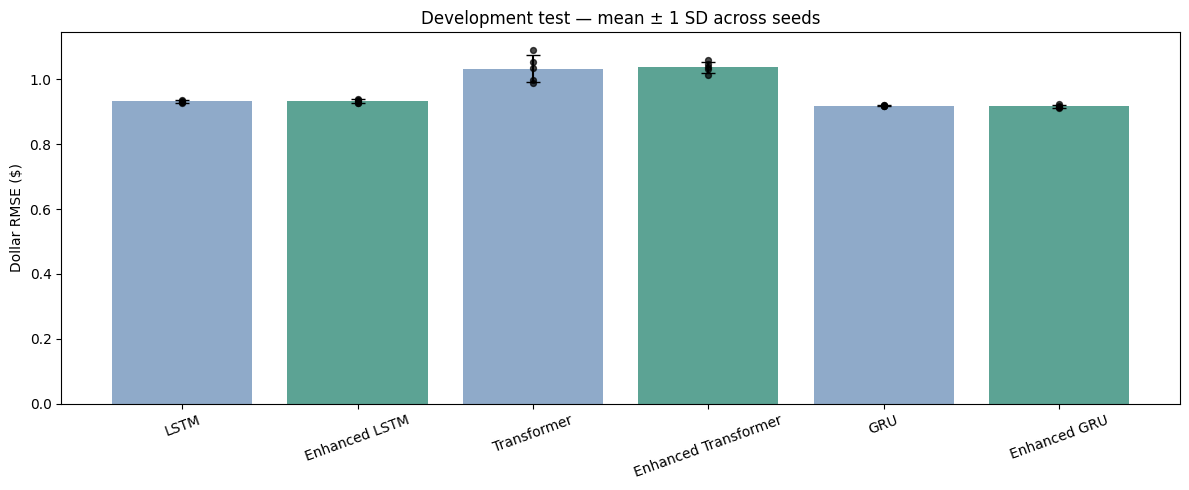

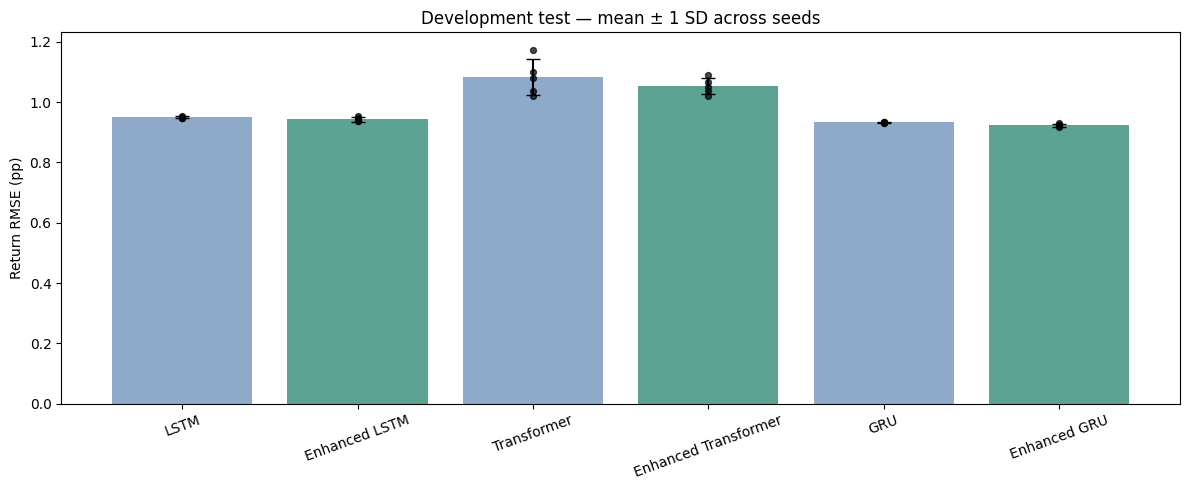

In [14]:
def summarize_runs(results, prefix):
    cols = [c for c in results.columns if c.startswith(prefix + " ")]
    summary = results.groupby("Model")[cols].agg(["mean", "std"]).reindex(MODEL_NAMES)
    summary.columns = [f"{c.removeprefix(prefix + ' ')} {stat}" for c, stat in summary.columns]
    return summary

def paired_metrics(results):
    rows = []
    metric_columns = [c for c in results if c.startswith(("Price ", "Return "))]
    for architecture in ARCHITECTURES:
        for metric in metric_columns:
            table = results.pivot(index="Seed", columns="Model", values=metric).reindex(SEEDS)
            for seed in SEEDS:
                base = table.loc[seed, architecture]
                enhanced = table.loc[seed, f"Enhanced {architecture}"]
                higher_better = metric.endswith("R²")
                improvement = enhanced - base if higher_better else base - enhanced
                rows.append({"Architecture": architecture, "Seed": seed, "Metric": metric,
                             "Price-only": base, "Enhanced": enhanced,
                             "Improvement (absolute)": improvement,
                             "Improvement (%)": improvement / base * 100 if not higher_better and base > 0 else np.nan})
    return pd.DataFrame(rows)

def report_runs(results, frame, stem):
    price_summary = summarize_runs(results, "Price")
    return_summary = summarize_runs(results, "Return")
    paired = paired_metrics(results)
    print("DOLLAR CLOSING PRICES — mean and sample standard deviation")
    display(price_summary.round(6))
    print("INTRADAY RETURNS — mean and sample standard deviation")
    display(return_summary.round(6))
    print("PAIRED RMSE COMPARISON BY SEED — positive reduction favors news-enhanced model")
    rmse = paired[paired["Metric"].isin(["Price RMSE ($)", "Return RMSE (pp)"])].copy()
    display(rmse.round(6).reset_index(drop=True))
    print("PAIRED IMPROVEMENT SUMMARY — ALL METRICS")
    summary = paired.groupby(["Architecture", "Metric"], sort=False).agg(
        Mean_Absolute_Improvement=("Improvement (absolute)", "mean"),
        SD_Absolute_Improvement=("Improvement (absolute)", "std"),
        Mean_Percent_Improvement=("Improvement (%)", "mean"),
        SD_Percent_Improvement=("Improvement (%)", "std"),
        Enhanced_Wins=("Improvement (absolute)", lambda x: (x > 0).sum()),
        Ties=("Improvement (absolute)", lambda x: (x == 0).sum()),
        Seeds=("Seed", "count")
    )
    display(summary.round(6))
    baseline_price, baseline_return, _, _ = compare_models(frame, {})
    print("DETERMINISTIC BENCHMARKS (same for all seeds)")
    display(baseline_price.round(6))
    display(baseline_return.round(6))
    for suffix, table in [("Price_Summary", price_summary), ("Return_Summary", return_summary),
                          ("Paired_All_Metrics", paired), ("Paired_Summary", summary), ("Price_Baselines", baseline_price),
                          ("Return_Baselines", baseline_return)]:
        table.to_csv(f"{stem}_{suffix}.csv")
    return price_summary, return_summary, paired

price_summary, return_summary, paired = report_runs(seed_results, test_raw, "AAPL_6Model_5Seed_Development")

for prefix, metric, unit in [("Price", "Price RMSE ($)", "Dollar RMSE ($)"),
                             ("Return", "Return RMSE (pp)", "Return RMSE (pp)")]:
    fig, ax = plt.subplots(figsize=(12, 5))
    grouped = seed_results.groupby("Model")[metric]
    means = grouped.mean().reindex(MODEL_NAMES)
    sds = grouped.std(ddof=1).reindex(MODEL_NAMES)
    ax.bar(MODEL_NAMES, means, yerr=sds, capsize=5, alpha=0.8,
           color=["#7395bc" if not name.startswith("Enhanced ") else "#338c79" for name in MODEL_NAMES])
    ax.tick_params(axis="x", labelrotation=20)
    for i, name in enumerate(MODEL_NAMES):
        ax.scatter([i] * len(SEEDS), seed_results.loc[seed_results.Model == name, metric], color="black", s=18, alpha=.7)
    ax.set_ylabel(unit)
    ax.set_title("Development test — mean ± 1 SD across seeds")
    plt.tight_layout()
    plt.show()


## Optional final validation — keep disabled for now
Once research settings are finalized, evaluate all five seeds for all six models using their saved weights and unchanged training-fitted scalers. Do not select the best seed. Keep the weights and result files in the current Colab runtime or back them up before disconnecting. This cell does not retrain.

In [15]:
RUN_FINAL_VALIDATION = False

if RUN_FINAL_VALIDATION:
    val_price = make_price_features(val_raw, previous_close.loc[val_raw.index])
    val_features = price_tensor(val_price)
    val_news = make_news_features(val_raw.index, scored_news)
    val_features_enhanced = torch.cat([val_features, news_tensor(val_news)], dim=1)
    final_rows = []
    for seed in SEEDS:
        for name in MODEL_NAMES:
            model = model_factories[name]().to(DEVICE)
            model.load_state_dict(torch.load(checkpoint_path(name, seed), map_location=DEVICE, weights_only=True))
            x_val = select_features(name, val_features, val_features_enhanced)
            pred = predict_normalized(model, x_val)
            final_rows.append(metric_row(name, seed, val_raw, pred))
            del model
    final_results = pd.DataFrame(final_rows)
    final_results.to_csv("AAPL_6Model_5Seed_Final_Validation_Per_Run.csv", index=False)
    final_price_summary, final_return_summary, final_paired = report_runs(final_results, val_raw, "AAPL_6Model_5Seed_Final_Validation")
else:
    print("Final validation remains reserved.")


Final validation remains reserved.


## Save your experiment outputs (optional)
Run this after the development experiment (and again after final validation, if desired) to download the checkpoint files and result CSVs together. Colab runtime files disappear when the session expires; keep the ZIP and the original sentiment CSV. To restore the experiment in a new session, retain the same raw data and preprocessing settings.

In [16]:
import zipfile
from pathlib import Path
from google.colab import files

archive = Path("AAPL_6Model_5Seed_Results.zip")
with zipfile.ZipFile(archive, "w", compression=zipfile.ZIP_DEFLATED) as z:
    for path in sorted(Path.cwd().glob("AAPL_6Model_5Seed_*.csv")):
        z.write(path, arcname=path.name)
    for path in sorted(CHECKPOINT_DIR.glob("*.pt")):
        z.write(path, arcname=str(path.relative_to(Path.cwd())) if path.is_absolute() else str(path))
    for name in ["AAPL_Training.csv", "AAPL_Testing.csv", "AAPL_Validation.csv"]:
        if Path(name).exists():
            z.write(name, arcname=name)
files.download(str(archive))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>